# Lesson 07 - Detecting unknown ships

A normal classifier must pick one of the classes it knows, even for a ship type it has never heard.
A sonar operator needs it to say **"unknown"** instead. This is called **open-set recognition**.

Two kinds of "new" (presentation slide 2):

| situation | wanted answer |
|---|---|
| a new tanker, when the model was trained on other tankers | "tanker" (the vessel-disjoint folds test this) |
| a fishing boat, when the model never saw *any* fishing boat | "unknown" |

To test the second, we **hold out whole classes**: group A (fishing, sailing, tanker), B (cargo,
pleasurecraft, rescue) and C (tug, passengership, other) are each removed from training in turn, and their
test clips must be flagged.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import reliability as R
from labels import load_groups
from paths import RUNS_DIR

GROUP_RUNS = {g: RUNS_DIR / f"class_f1_efficientnet_b0_vessel_h{g}" for g in "ABC"}
for g, members in load_groups().items():
    print(f"group {g}: held out = {', '.join(members)}")

group A: held out = fishing, sailing, tanker
group B: held out = cargo, pleasurecraft, rescue
group C: held out = tug, passengership, other


## 1. Two scores for "how unknown is this clip?"

The network outputs one **logit** (raw score) per known class. Softmax turns them into probabilities.

- **MSP** (maximum softmax probability, the baseline): unknown score = 1 − highest probability.
- **Energy**: `−logsumexp(logits)`. Softmax only looks at the *differences* between logits, so a clip where
  every logit is low (nothing matches) can still get a confident-looking softmax. Energy uses the raw size of
  the logits, which often separates unknowns better.

In [2]:
examples = {"clear match": [9.0, 1, 1, 1], "two similar classes": [5.0, 4.8, 1, 1], "nothing matches": [1.2, 1.0, 0.9, 1.1],
            "nothing matches, but one slightly higher": [1.0, -2, -2, -2]}
pd.DataFrame({name: {"MSP score (1 - max prob)": round(float(R.msp_score(np.array([l]))[0]), 3),
                     "energy score": round(float(R.energy_score(np.array([l]))[0]), 2)} for name, l in examples.items()}).T

,MSP score (1 - max prob),energy score
clear match,0.001,-9.00
two similar classes,0.461,-5.62
nothing matches,0.711,-2.44
"nothing matches, but one slightly higher",0.130,-1.14


Look at the last row: the softmax says "fairly sure" (low MSP score), but the energy is high (unknown-like),
because all logits are small. That's the case energy is designed to catch.

## 2. How we measure it

- **AUROC**: the chance that a random unknown clip gets a higher unknown score than a random known clip.
  0.5 = guessing, 1.0 = perfect.
- **FPR at 95 % TPR**: set the threshold so 95 % of known clips are accepted; what fraction of unknown clips
  slip through as "known"? Lower is better.
- **Open-set accuracy**: with the threshold chosen on *validation*, a test clip counts as correct if it is
  unknown and flagged, or known, accepted and given the right class.

Train and evaluate the three groups (MC dropout adds two more scores; see lesson 08):
```
python src/train.py --task class --holdout A
python src/evaluate.py runs/class_f1_efficientnet_b0_vessel_hA --mc 20
```
(repeat with B and C). For the **deep ensemble** row, train two more group-A models and evaluate them together:
```
python src/train.py --task class --holdout A --seed 1
python src/train.py --task class --holdout A --seed 2
python src/evaluate.py runs/class_f1_efficientnet_b0_vessel_hA --mc 20 \
    --ensemble runs/class_f1_efficientnet_b0_vessel_hA_s1 runs/class_f1_efficientnet_b0_vessel_hA_s2
```

In [3]:
rows = []
for g, run in GROUP_RUNS.items():
    m_path = run / "eval" / "metrics.json"
    if not m_path.exists():
        print(f"no run yet for group {g}:  python src/train.py --task class --holdout {g}  then  "
              f"python src/evaluate.py {run.relative_to(ROOT).as_posix()} --mc 20")
        continue
    os_ = json.loads(m_path.read_text())["open_set"]
    for score, v in os_.items():
        if isinstance(v, dict):
            rows.append({"group": g, "score": score, "AUROC": round(v["auroc"], 3), "FPR95": round(v["fpr95"], 3)})
    rows.append({"group": g, "score": "open-set acc (energy)", "AUROC": round(os_["open_set_accuracy_energy"], 3), "FPR95": None})
if rows:
    res = pd.DataFrame(rows)
    display(res.pivot(index="score", columns="group", values="AUROC").assign(mean=lambda d: d.mean(axis=1).round(3)))
    display(res.dropna().pivot(index="score", columns="group", values="FPR95"))

group,A,B,C,mean
score,,,,
energy,0.525,0.579,0.569,0.558
mc_entropy,0.506,0.589,0.507,0.534
mc_mi,0.482,0.473,0.558,0.504
msp,0.500,0.579,0.508,0.529
open-set acc (energy),0.323,0.324,0.319,0.322


group,A,B,C
score,,,
energy,0.925,0.941,0.898
mc_entropy,0.920,0.875,0.936
mc_mi,0.958,0.967,0.905
msp,0.926,0.891,0.935


## 3. Known vs unknown, visually

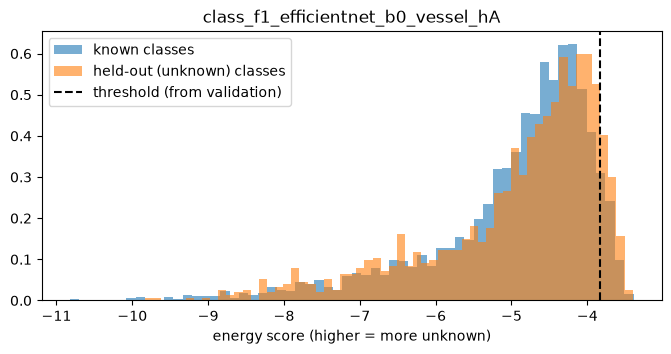

per held-out class, fraction flagged unknown:
label
fishing    0.147
sailing    0.102
tanker     0.040


In [4]:
run = next((r for r in GROUP_RUNS.values() if (r / "eval" / "predictions.parquet").exists()), None)
if run is None:
    print("no evaluated holdout run yet (see the commands above)")
else:
    p = pd.read_parquet(run / "eval" / "predictions.parquet")
    cal = json.loads((run / "eval" / "calibration.json").read_text())
    unknown = p.y_class == -1
    plt.figure(figsize=(8, 3.5))
    plt.hist(p.energy[~unknown], bins=60, alpha=0.6, density=True, label="known classes")
    plt.hist(p.energy[unknown], bins=60, alpha=0.6, density=True, label="held-out (unknown) classes")
    plt.axvline(cal["energy_threshold"], c="k", ls="--", label="threshold (from validation)")
    plt.xlabel("energy score (higher = more unknown)"); plt.legend(); plt.title(run.name); plt.show()
    print("per held-out class, fraction flagged unknown:")
    print((p[unknown].energy > cal["energy_threshold"]).groupby(p[unknown].label).mean().round(3).to_string())

## Try it

1. Which held-out group is hardest to detect? Is it a group whose ships sound like a known class
   (e.g. a tanker held out while cargo is known)?
2. Open `eval/open_set_roc.png` for each group and compare the MSP and energy curves.
3. Does the presentation's goal, "flag unknown ships better than softmax", hold for all three groups?